# WellSense · Notebook 1 — ETL Pipeline
**WellSense: A Hybrid Knowledge-Based System for Fault Diagnosis and Maintenance Decision Support in Offshore Oil Wells**

This notebook turns raw Petrobras 3W sensor data into clean, trustworthy facts that the knowledge-based system can reason about.

| Stage | What happens |
|---|---|
| **E — Extract** | Load the approved CSV (real Petrobras well instances), check its schema, and profile how dirty it is |
| **T — Transform** | Fix the time grid, remove error codes and impossible values, detect frozen sensors and spikes, classify missing data, convert units, learn thresholds from normal operation, engineer features, and convert numbers into symbolic facts with quality tags |
| **L — Load** | Store everything in one SQLite database (`db/wellsense.db`) and produce a before/after data-quality report |

**Source:** Petrobras 3W Dataset v2.0.0 — https://github.com/petrobras/3W (CC BY 4.0). Only *real* instances are used.

## 0. Setup
Choose **one** way to give Colab the project files, then run the cells in order (Runtime → Run all):

| `SOURCE` | When to use | What to do |
|---|---|---|
| `'drive'` | The `WellSense` folder is in the Google Drive of the account you are using Colab with | Put the folder at *My Drive/WellSense* and allow Drive access when asked |
| `'upload'` | Your files are on another account, or you don't want to use Drive | Run the cell and choose `WellSense_Stage1_ETL.zip` from your computer. **Note:** uploaded files disappear when Colab disconnects, so download `db/wellsense.db` and the `outputs` folder at the end |

Running on your own computer instead of Colab? Nothing to change.

In [1]:
SOURCE = 'drive'          # 'drive' or 'upload'

import os, sys, zipfile

try:
    import google.colab   # only exists inside Colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if not IN_COLAB:
    PROJECT_DIR = os.getcwd()
elif SOURCE == 'drive':
    from google.colab import drive
    drive.mount('/content/drive')
    # Find the WellSense folder, even if it ended up one level deeper (e.g. MyDrive/WellSense/WellSense)
    import glob
    _cands = ['/content/drive/MyDrive/WellSense'] + sorted(glob.glob('/content/drive/MyDrive/WellSense*')) \
             + sorted(glob.glob('/content/drive/MyDrive/*/WellSense*'))
    _cands += [c + '/WellSense' for c in list(_cands)]
    _found = [c for c in _cands if os.path.isfile(os.path.join(c, 'wellsense', '__init__.py'))]
    if not _found:
        raise FileNotFoundError("WellSense folder not found in My Drive. Upload the WHOLE unzipped WellSense folder "
                                "(it must contain the folders 'wellsense', 'data' and 'knowledge_base') to My Drive.")
    PROJECT_DIR = _found[0]
    print('Project folder:', PROJECT_DIR)
else:
    from google.colab import files
    PROJECT_DIR = '/content/WellSense'
    if not os.path.exists(PROJECT_DIR):
        print('Choose the WellSense zip file from your computer...')
        for name in files.upload():
            zipfile.ZipFile(name).extractall('/content')
            os.remove(name)

if not os.path.exists(os.path.join(PROJECT_DIR, 'data', '3W_real_small.csv')):
    raise FileNotFoundError(
        f"Could not find data/3W_real_small.csv inside {PROJECT_DIR}. "
        "With SOURCE='drive', upload the WellSense folder to My Drive first; "
        "otherwise set SOURCE='upload' and choose the zip file.")
os.chdir(PROJECT_DIR)
for d in ['db', 'outputs/figures', 'outputs/tables']:
    os.makedirs(d, exist_ok=True)
print('Working in:', os.getcwd())

Working in: /content/drive/MyDrive/WellSense


In [2]:
import json, shutil, sqlite3, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})

# Which input file to use. The small file is used for building and the demo;
# set USE_FULL_DATA = True to re-run the same pipeline on all 1,119 real instances.
USE_FULL_DATA = False
INPUT_FILE = 'data/3W_real_instances_1min.csv' if USE_FULL_DATA else 'data/3W_real_small.csv'
DB_PATH = 'db/wellsense_full.db' if USE_FULL_DATA else 'db/wellsense.db'
print('Input :', INPUT_FILE)
print('Output:', DB_PATH)

Input : data/3W_real_small.csv
Output: db/wellsense.db


---
# E — EXTRACT
## E1. Load the raw data and the data dictionary

In [3]:
raw = pd.read_csv(INPUT_FILE, low_memory=False)
dictionary = pd.read_csv('data/3W_data_dictionary.csv')

ID_COLS = ['instance_id', 'well_id', 'event_type', 'event_name', 'timestamp']
LABEL_COLS = ['class', 'state']
SENSOR_TAGS = [c for c in raw.columns if c not in ID_COLS + LABEL_COLS]

print(f'Rows: {len(raw):,}   Columns: {raw.shape[1]}   Sensor/valve variables: {len(SENSOR_TAGS)}')
print(f'Real instances: {raw.instance_id.nunique()}   Wells: {raw.well_id.nunique()}')
raw.head(3)

Rows: 65,846   Columns: 34   Sensor/valve variables: 27
Real instances: 125   Wells: 40


,instance_id,well_id,event_type,event_name,timestamp,ABER-CKGL,ABER-CKP,ESTADO-DHSV,ESTADO-M1,ESTADO-M2,ESTADO-PXO,ESTADO-SDV-GL,ESTADO-SDV-P,ESTADO-W1,ESTADO-W2,ESTADO-XO,P-ANULAR,P-JUS-BS,P-JUS-CKGL,P-JUS-CKP,P-MON-CKGL,P-MON-CKP,P-MON-SDV-P,P-PDG,PT-P,P-TPT,QBS,QGL,T-JUS-CKP,T-MON-CKP,T-PDG,T-TPT,class,state
0,WELL-00001_20170201010207,WELL-00001,0,NORMAL,2017-02-01 01:02:07,NaN,NaN,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,12767730.0,NaN,1563422.0,NaN,NaN,1627884.0,NaN,0.0,NaN,10074540.0,NaN,0.0,84.64463,NaN,0.0,119.0781,NaN,NaN
1,WELL-00001_20170201010207,WELL-00001,0,NORMAL,2017-02-01 01:03:00,NaN,NaN,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,12767730.0,NaN,1563432.0,NaN,NaN,1773032.0,NaN,0.0,NaN,10074540.0,NaN,0.0,84.71368,NaN,0.0,119.0783,NaN,NaN
2,WELL-00001_20170201010207,WELL-00001,0,NORMAL,2017-02-01 01:04:00,NaN,NaN,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,12767730.0,NaN,1563445.0,NaN,NaN,1474208.0,NaN,0.0,NaN,10074540.0,NaN,0.0,84.00451,NaN,0.0,119.0786,NaN,NaN


## E2. Schema check
Every column in the file must be documented in the data dictionary, and every variable must be numeric.

In [4]:
undocumented = set(raw.columns) - set(dictionary['column'])
non_numeric = [c for c in SENSOR_TAGS + LABEL_COLS if not pd.api.types.is_numeric_dtype(raw[c])]
print('Undocumented columns:', undocumented or 'none')
print('Non-numeric variables:', non_numeric or 'none')
assert not undocumented and not non_numeric

Undocumented columns: none
Non-numeric variables: none


## E3. What is in the data?
Instances per event type (each instance is one real event recorded on one well).

In [5]:
overview = (raw.groupby(['event_type', 'event_name'])
              .agg(instances=('instance_id', 'nunique'), wells=('well_id', 'nunique'), rows=('instance_id', 'size'))
              .reset_index())
overview

,event_type,event_name,instances,wells,rows
0,0,NORMAL,15,9,4726
1,1,ABRUPT_INCREASE_OF_BSW,4,3,2294
2,2,SPURIOUS_CLOSURE_OF_DHSV,15,7,3639
3,3,SEVERE_SLUGGING,15,2,5335
4,4,FLOW_INSTABILITY,15,7,2707
5,5,RAPID_PRODUCTIVITY_LOSS,11,3,5910
6,6,QUICK_RESTRICTION_IN_PCK,6,2,1284
7,7,SCALING_IN_PCK,15,6,16150
8,8,HYDRATE_IN_PRODUCTION_LINE,14,9,16800
9,9,HYDRATE_IN_SERVICE_LINE,15,15,7001


## E4. Raw data-quality profile (the "before" picture)
Two kinds of missing data are separated here:
* **Not installed** — the variable is empty for a whole instance (that well simply has no such sensor).
* **Gaps** — the variable has some readings but some are missing.

In [6]:
def missing_profile(df, tags):
    rows = []
    for tag in tags:
        per_inst = df.groupby('instance_id')[tag].apply(lambda s: s.isna().all())
        rows.append({
            'variable': tag,
            'missing_%': round(df[tag].isna().mean() * 100, 1),
            'instances_not_installed': int(per_inst.sum()),
            'instances_with_sensor': int((~per_inst).sum()),
        })
    return pd.DataFrame(rows).set_index('variable')

raw_profile = missing_profile(raw, SENSOR_TAGS)
raw_profile.sort_values('missing_%')

,missing_%,instances_not_installed,instances_with_sensor
variable,,,
P-MON-CKP,6.8,17,108
P-JUS-CKGL,12.5,31,94
ESTADO-SDV-P,13.0,28,97
T-TPT,14.1,11,114
P-TPT,14.3,12,113
P-PDG,18.1,17,108
T-PDG,18.5,26,99
QGL,24.3,38,87
ESTADO-W1,25.9,38,87


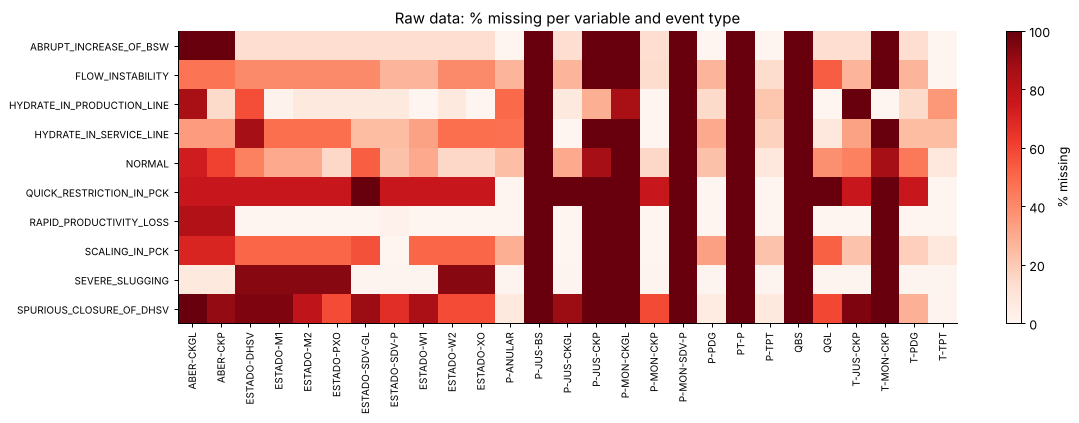

In [7]:
heat = raw.groupby('event_name')[SENSOR_TAGS].apply(lambda g: g.isna().mean() * 100)
fig, ax = plt.subplots(figsize=(13, 4.8))
im = ax.imshow(heat.values, aspect='auto', cmap='Reds', vmin=0, vmax=100)
ax.set_xticks(range(len(SENSOR_TAGS)), SENSOR_TAGS, rotation=90, fontsize=8)
ax.set_yticks(range(len(heat.index)), heat.index, fontsize=8)
ax.set_title('Raw data: % missing per variable and event type')
fig.colorbar(im, ax=ax, label='% missing')
plt.tight_layout(); plt.savefig('outputs/figures/01_raw_missingness_heatmap.png', dpi=150); plt.show()

**Labels:** `class` = 0 normal, *N* = event *N* established, 100+*N* = event *N* developing (transient), empty = not labelled by Petrobras.

In [8]:
print('Unlabelled rows:', f"{raw['class'].isna().mean():.1%}")
print('Rows with unknown well state:', f"{raw['state'].isna().mean():.1%}")

Unlabelled rows: 8.5%
Rows with unknown well state: 8.5%


---
# T — TRANSFORM
## T1. Structural cleaning
* Drop variables that are empty for **every** instance (no information at all).
* Remove duplicate observations.
* Align timestamps to a regular 1-minute grid and sort.

In [9]:
df = raw.copy()
df['timestamp'] = pd.to_datetime(df['timestamp']).dt.floor('min')

empty_cols = [t for t in SENSOR_TAGS if df[t].isna().all()]
df = df.drop(columns=empty_cols)
TAGS = [t for t in SENSOR_TAGS if t not in empty_cols]

n_before = len(df)
df = df.drop_duplicates(['instance_id', 'timestamp']).sort_values(['instance_id', 'timestamp']).reset_index(drop=True)

gaps = df.groupby('instance_id')['timestamp'].diff().dt.total_seconds().div(60)
print('Dropped empty columns:', empty_cols)
print('Duplicate observations removed:', n_before - len(df))
print('Time gaps longer than 1 minute:', int((gaps > 1).sum()))
print('Variables kept:', len(TAGS))

Dropped empty columns: ['P-JUS-BS', 'P-MON-SDV-P', 'PT-P', 'QBS']
Duplicate observations removed: 0
Time gaps longer than 1 minute: 0
Variables kept: 23


## T2. Readable names and variable types
Petrobras tags are in Portuguese (e.g. *ESTADO* = state, *MON* = upstream, *JUS* = downstream). Each one gets a readable name and a type, which decides how it is cleaned.

In [10]:
VARIABLES = pd.DataFrame([
    # tag,          name,        type,        unit,  equipment / location
    ('P-PDG',      'p_pdg',      'pressure',  'bar', 'Permanent downhole gauge (PDG)'),
    ('T-PDG',      't_pdg',      'temperature','degC','Permanent downhole gauge (PDG)'),
    ('P-TPT',      'p_tpt',      'pressure',  'bar', 'Subsea Xmas tree (TPT)'),
    ('T-TPT',      't_tpt',      'temperature','degC','Subsea Xmas tree (TPT)'),
    ('P-MON-CKP',  'p_mon_ckp',  'pressure',  'bar', 'Production choke (PCK), upstream'),
    ('T-MON-CKP',  't_mon_ckp',  'temperature','degC','Production choke (PCK), upstream'),
    ('P-JUS-CKP',  'p_jus_ckp',  'pressure',  'bar', 'Production choke (PCK), downstream'),
    ('T-JUS-CKP',  't_jus_ckp',  'temperature','degC','Production choke (PCK), downstream'),
    ('P-MON-CKGL', 'p_mon_ckgl', 'pressure',  'bar', 'Gas-lift choke (GLCK), upstream'),
    ('P-JUS-CKGL', 'p_jus_ckgl', 'pressure',  'bar', 'Gas-lift choke (GLCK), downstream'),
    ('P-ANULAR',   'p_anular',   'pressure',  'bar', 'Well annulus'),
    ('QGL',        'qgl',        'flow',      'm3/s','Gas-lift line'),
    ('ABER-CKP',   'aber_ckp',   'opening',   '%',   'Production choke (PCK)'),
    ('ABER-CKGL',  'aber_ckgl',  'opening',   '%',   'Gas-lift choke (GLCK)'),
    ('ESTADO-DHSV','dhsv_state', 'valve',     '0/0.5/1','Downhole safety valve (DHSV)'),
    ('ESTADO-M1',  'pmv_state',  'valve',     '0/0.5/1','Production master valve (PMV)'),
    ('ESTADO-M2',  'amv_state',  'valve',     '0/0.5/1','Annulus master valve (AMV)'),
    ('ESTADO-PXO', 'pxo_state',  'valve',     '0/0.5/1','Pig-crossover valve (PXO)'),
    ('ESTADO-SDV-GL','sdv_gl_state','valve',  '0/0.5/1','Gas-lift shutdown valve (SDV-GL)'),
    ('ESTADO-SDV-P','sdv_p_state','valve',    '0/0.5/1','Production shutdown valve (SDV-P)'),
    ('ESTADO-W1',  'pwv_state',  'valve',     '0/0.5/1','Production wing valve (PWV)'),
    ('ESTADO-W2',  'awv_state',  'valve',     '0/0.5/1','Annulus wing valve (AWV)'),
    ('ESTADO-XO',  'xo_state',   'valve',     '0/0.5/1','Crossover valve (XO)'),
], columns=['tag', 'name', 'type', 'unit', 'equipment'])
VARIABLES = VARIABLES[VARIABLES.tag.isin(TAGS)].reset_index(drop=True)
assert len(VARIABLES) == len(TAGS), set(TAGS) - set(VARIABLES.tag)

df = df.rename(columns=dict(zip(VARIABLES.tag, VARIABLES.name)))
NAMES = list(VARIABLES.name)
TYPE = dict(zip(VARIABLES.name, VARIABLES.type))
ANALOG = [n for n in NAMES if TYPE[n] in ('pressure', 'temperature', 'flow')]
VARIABLES[['tag', 'name', 'type', 'unit', 'equipment']]

,tag,name,type,unit,equipment
0,P-PDG,p_pdg,pressure,bar,Permanent downhole gauge (PDG)
1,T-PDG,t_pdg,temperature,degC,Permanent downhole gauge (PDG)
2,P-TPT,p_tpt,pressure,bar,Subsea Xmas tree (TPT)
3,T-TPT,t_tpt,temperature,degC,Subsea Xmas tree (TPT)
4,P-MON-CKP,p_mon_ckp,pressure,bar,"Production choke (PCK), upstream"
5,T-MON-CKP,t_mon_ckp,temperature,degC,"Production choke (PCK), upstream"
6,P-JUS-CKP,p_jus_ckp,pressure,bar,"Production choke (PCK), downstream"
7,T-JUS-CKP,t_jus_ckp,temperature,degC,"Production choke (PCK), downstream"
8,P-MON-CKGL,p_mon_ckgl,pressure,bar,"Gas-lift choke (GLCK), upstream"
9,P-JUS-CKGL,p_jus_ckgl,pressure,bar,"Gas-lift choke (GLCK), downstream"


## T3. Unit conversion
Pressures are stored in pascals (e.g. 18,814,780 Pa). Engineers read them in **bar** (1 bar = 100,000 Pa), so they are converted. Temperatures stay in °C.

In [11]:
PRESSURES = [n for n in NAMES if TYPE[n] == 'pressure']
df[PRESSURES] = df[PRESSURES] / 1e5
RAW_PRESENT = df[NAMES].notna()   # remember which readings existed before any cleaning
df[['p_pdg', 'p_tpt', 'p_mon_ckp']].describe().round(1)

,p_pdg,p_tpt,p_mon_ckp
count,5.395200e+04,56443.0,61342.0
mean,-5.903642e+35,347.3,35.4
std,2.572659e+36,2505.6,29.1
min,-1.180116e+37,-171.3,-0.1
25%,0.000000e+00,87.3,14.9
50%,1.476000e+02,129.3,25.1
75%,2.447000e+02,175.1,41.4
max,4.842000e+02,29419.9,143.2


The minimum P-PDG above is an absurd number (about −10³⁷ bar). The data clearly contains error codes and impossible readings — handled next.

## T4. Invalid values: error codes and physically impossible readings
A reading is **invalid** if it is a known error code, or falls outside the range that is physically possible for that measurement. Invalid readings are set to empty and recorded.

| Check | Rule | Why |
|---|---|---|
| Error codes | −9,999,000 Pa, −99.99 °C, 30,000 °C, any magnitude ≥ 10¹⁰ | Values written by the data system when a sensor fails |
| Pressure | must be > 0 and ≤ 1,000 bar | Absolute pressure cannot be zero or negative; offshore wells do not exceed ~1,000 bar |
| Downhole pressure (P-PDG) | > 10 bar | The gauge sits thousands of metres down; the fluid column above it alone is far above 10 bar, so ~0 means a dead gauge |
| Downhole temperature (T-PDG) | > 20 and ≤ 200 °C | Deep underground is always far warmer than the ~4 °C seabed; readings near 0 °C mean a faulty gauge |
| Subsea temperature (T-TPT) | 0 – 200 °C | Seabed water does not go below freezing |
| Topside temperatures | −5 – 150 °C | Platform conditions |
| Gas-lift flow | 0 – 20 m³/s | Cannot be negative |
| Choke opening | 0 – 100 % | It is a percentage |
| Valve states | 0, 0.5 or 1 | Closed, intermediate, open |

In [12]:
VALID_RANGE = {          # (min, max, min_is_exclusive)
    'pressure': (0, 1000, True), 'p_pdg': (10, 1000, True),
    't_pdg': (20, 200, True), 't_tpt': (0, 200, False),
    't_mon_ckp': (-5, 150, False), 't_jus_ckp': (-5, 150, False),
    'flow': (0, 20, False), 'opening': (0, 100, False),
}
ERROR_CODES_RAW = {-9999000.0, -99.99, 30000.0}

# Quality code for every single value. Starts as OK where a reading exists.
Q = pd.DataFrame('OK', index=df.index, columns=NAMES)
Q[df[NAMES].isna()] = 'NA'          # refined later into NOT_INSTALLED / GAP

log = {n: {} for n in NAMES}
for n in NAMES:
    tag = VARIABLES.set_index('name').loc[n, 'tag']
    x = df[n]
    if TYPE[n] == 'valve':
        bad = x.notna() & ~x.isin([0, 0.5, 1])
        log[n]['error_code'] = 0
    else:
        lo, hi, excl = VALID_RANGE.get(n, VALID_RANGE.get(TYPE[n]))
        scale = 1e5 if TYPE[n] == 'pressure' else 1
        is_code = x.notna() & ((x * scale).round(2).isin(ERROR_CODES_RAW) | ((x * scale).abs() >= 1e10))
        too_low = (x <= lo) if excl else (x < lo)
        out_of_range = x.notna() & (too_low | (x > hi))
        bad = is_code | out_of_range
        log[n]['error_code'] = int(is_code.sum())
    log[n]['invalid_total'] = int(bad.sum())
    df.loc[bad, n] = np.nan
    Q.loc[bad, n] = 'INVALID'

invalid_report = pd.DataFrame(log).T
invalid_report[invalid_report.invalid_total > 0].sort_values('invalid_total', ascending=False)

,error_code,invalid_total
p_pdg,2699,21011
t_pdg,7497,20459
p_tpt,0,5659
t_tpt,0,5403
p_jus_ckp,1200,5058
p_anular,0,1580
p_jus_ckgl,0,1262
aber_ckp,1200,1200
t_mon_ckp,1200,1200
t_jus_ckp,0,124


## T5. Frozen sensors
A frozen (stuck) sensor keeps sending the same number even though the process is changing. Real measurements always carry small noise, so **the exact same reading for 60 minutes or more** is treated as frozen.

* Applied only to measured process variables (pressures, temperatures, gas-lift flow).
* Not applied to choke openings or valve states — those are set by operators and are *supposed* to stay constant.
* Gas-lift flow of exactly 0 is *gas lift switched off*, not a frozen meter.

Frozen values are **kept but marked untrusted** (quality `FROZEN`). The KBS will later give them very low weight, which is how it handles conflicting evidence.

In [13]:
FROZEN_MIN_RUN = 60  # minutes

def frozen_mask(series, groups, min_run, ignore_value=None):
    s = series
    new_run = (s != s.groupby(groups).shift()) | s.isna()
    run_id = new_run.cumsum()
    run_len = s.groupby(run_id).transform('size')
    mask = s.notna() & (run_len >= min_run)
    if ignore_value is not None:
        mask &= s != ignore_value
    return mask

for n in ANALOG:
    m = frozen_mask(df[n], df['instance_id'], FROZEN_MIN_RUN, ignore_value=0 if TYPE[n] == 'flow' else None)
    Q.loc[m, n] = 'FROZEN'
    log[n]['frozen'] = int(m.sum())

frozen_report = pd.Series({n: log[n]['frozen'] for n in ANALOG}, name='frozen_readings').sort_values(ascending=False)
frozen_report.to_frame().assign(pct_of_readings=lambda t: (t.frozen_readings / df[ANALOG].notna().sum() * 100).round(1))

,frozen_readings,pct_of_readings
t_pdg,8714,26.3
p_pdg,8000,24.3
p_tpt,4770,9.4
t_tpt,3706,7.2
p_anular,2985,6.5
p_mon_ckp,619,1.0
qgl,606,1.2
p_jus_ckp,235,3.1
t_mon_ckp,174,1.1
p_jus_ckgl,165,0.3


## T6. Spikes (isolated outliers)
A **spike** is a single reading that jumps far away from both of its neighbours, while the neighbours agree with each other — typical of electrical noise or a transmission error.

Important: real faults also cause big changes, but a fault *stays* changed. Only one-point spikes are removed, so genuine event behaviour is never deleted.

In [14]:
SPIKE_K = 10  # how many 'typical minute-to-minute changes' a spike must exceed

def spike_mask(x, groups):
    prev, nxt = x.groupby(groups).shift(1), x.groupby(groups).shift(-1)
    d1, d2 = x - prev, x - nxt
    typical = x.groupby(groups).transform(lambda s: (s.diff().abs().median() * 1.4826) or s.diff().abs().mean() or 0)
    floor = 0.05 * x.groupby(groups).transform(lambda s: s.abs().median())
    scale = np.maximum(typical, floor.fillna(0)) + 1e-9
    return (np.sign(d1) == np.sign(d2)) & (d1.abs() > SPIKE_K * scale) & (d2.abs() > SPIKE_K * scale) \
           & ((prev - nxt).abs() < 0.25 * np.minimum(d1.abs(), d2.abs()))

for n in ANALOG:
    m = spike_mask(df[n].where(Q[n] == 'OK'), df['instance_id']).fillna(False)
    df.loc[m, n] = np.nan
    Q.loc[m, n] = 'SPIKE'
    log[n]['spikes'] = int(m.sum())

pd.Series({n: log[n]['spikes'] for n in ANALOG}, name='spikes_removed')

p_pdg          10
t_pdg         116
p_tpt           0
t_tpt           0
p_mon_ckp      20
t_mon_ckp       0
p_jus_ckp       0
t_jus_ckp       0
p_mon_ckgl      0
p_jus_ckgl      0
p_anular        0
qgl           105

## T7. Missing data — classify, then fill only what is safe to fill
| Situation | Decision | Quality code |
|---|---|---|
| Variable never recorded in the **whole instance** | Sensor not installed on that well — never invented | `NOT_INSTALLED` |
| Sensor recorded values but **all were invalid or frozen** | Failed sensor — counted separately, never invented | stays `INVALID` / `FROZEN` |
| Gap of **≤ 5 minutes** (incl. removed spikes / invalid readings) | Linear interpolation between the neighbouring good readings | `INTERP` |
| Gap **> 5 minutes** | Left empty — too long to guess safely | `GAP` |
| Valve states | Carried forward (a valve keeps its last state until it changes), max 5 minutes | `INTERP` |

In [15]:
MAX_FILL = 5  # minutes
for n in NAMES:
    x = df[n]
    never_recorded = ~RAW_PRESENT[n].groupby(df['instance_id']).transform('any')
    if TYPE[n] == 'valve':
        filled = x.groupby(df['instance_id']).ffill(limit=MAX_FILL)
    else:
        filled = x.groupby(df['instance_id']).transform(
            lambda s: s.interpolate(limit=MAX_FILL, limit_area='inside'))
    newly = x.isna() & filled.notna()
    df[n] = filled
    log[n]['interpolated'] = int(newly.sum())
    Q.loc[newly, n] = 'INTERP'
    still_missing = df[n].isna()
    Q.loc[still_missing & never_recorded, n] = 'NOT_INSTALLED'
    Q.loc[still_missing & ~never_recorded & Q[n].isin(['NA']), n] = 'GAP'
    # INVALID / SPIKE values that could not be filled keep their code

# A variable whose readings were ALL invalid or frozen in an instance is a failed sensor, not a missing one
for n in ANALOG:
    usable = Q[n].isin(['OK', 'INTERP'])
    failed = (~usable).groupby(df['instance_id']).transform('all') & Q[n].isin(['INVALID', 'FROZEN', 'SPIKE'])
    log[n]['instances_failed_sensor'] = int(df.loc[failed, 'instance_id'].nunique())

pd.DataFrame({n: Q[n].value_counts() for n in NAMES}).T.reindex(
    columns=['OK', 'INTERP', 'FROZEN', 'INVALID', 'SPIKE', 'GAP', 'NOT_INSTALLED']).fillna(0).astype(int)

,OK,INTERP,FROZEN,INVALID,SPIKE,GAP,NOT_INSTALLED
p_pdg,24931,29,8000,21011,0,1741,10134
t_pdg,24355,137,8714,20459,0,1768,10413
p_tpt,46014,31,4770,5659,0,33,9339
t_tpt,47422,35,3706,5399,0,33,9251
p_mon_ckp,60675,55,619,18,0,11,4468
t_mon_ckp,16023,3,174,1200,0,0,48446
p_jus_ckp,7304,28,235,5033,0,0,53246
t_jus_ckp,35513,18,0,124,0,11,30180
p_mon_ckgl,2400,0,0,0,0,0,63446
p_jus_ckgl,56206,19,165,1262,0,11,8183


## T8. Labels and well state
* `event_label` = which event the row belongs to (0–9), `phase` = normal / transient / steady / unlabelled.
* `state` codes are turned into names (from the 3W 2.0 paper, Table 5).
* Unlabelled rows are kept for diagnosis but **excluded from evaluation**, because their true answer is unknown.

In [16]:
STATE_NAMES = {0: 'Open', 1: 'Shut-In', 2: 'Flushing Diesel', 3: 'Flushing Gas', 4: 'Bullheading',
               5: 'Closed With Diesel', 6: 'Closed With Gas', 7: 'Restart', 8: 'Depressurization'}
cls = df['class']
df['phase'] = np.select([cls.isna(), cls == 0, cls >= 100], ['unlabelled', 'normal', 'transient'], 'steady')
df['event_label'] = (cls % 100).astype('Int64')
df['well_state'] = df['state'].map(STATE_NAMES).fillna('Unknown')
pd.crosstab(df['event_name'], df['phase'])

phase,normal,steady,transient,unlabelled
event_name,,,,
ABRUPT_INCREASE_OF_BSW,979,165,1089,61
FLOW_INSTABILITY,0,1795,0,912
HYDRATE_IN_PRODUCTION_LINE,4200,0,12600,0
HYDRATE_IN_SERVICE_LINE,4559,35,1782,625
NORMAL,3815,0,0,911
QUICK_RESTRICTION_IN_PCK,600,221,110,353
RAPID_PRODUCTIVITY_LOSS,1100,189,3953,668
SCALING_IN_PCK,3721,45,12134,250
SEVERE_SLUGGING,0,4422,0,913


## T9. Instance metadata
For every instance: its well, event, duration and **fault onset** (first minute that Petrobras labelled as abnormal).

**Data finding:** some event instances (all of them *hydrate in service line*) contain **no abnormal label at all** — every observation is labelled normal. They are flagged `labels_consistent = False`, so the evaluation can report them separately instead of counting them as hits or misses.

In [17]:
def onset(g):
    ab = g.loc[g['class'].notna() & (g['class'] != 0), 'timestamp']
    return ab.iloc[0] if len(ab) else pd.NaT

instances = (df.groupby('instance_id')
               .agg(well_id=('well_id', 'first'), event_type=('event_type', 'first'),
                    event_name=('event_name', 'first'), start=('timestamp', 'min'),
                    end=('timestamp', 'max'), minutes=('timestamp', 'size'))
               .reset_index())
instances['fault_onset'] = instances['instance_id'].map(df.groupby('instance_id').apply(onset))
instances['onset_minute'] = ((instances['fault_onset'] - instances['start']).dt.total_seconds() // 60)
# An event instance whose observations are ALL labelled normal has no labelled fault period to evaluate against
instances['labels_consistent'] = (instances['event_type'] == 0) | instances['fault_onset'].notna()
print('Event instances with no abnormal label at all (label-inconsistent):',
      int((~instances['labels_consistent']).sum()), '—', instances.loc[~instances['labels_consistent'], 'event_name'].value_counts().to_dict())
instances.head()

Event instances with no abnormal label at all (label-inconsistent): 8 — {'HYDRATE_IN_SERVICE_LINE': 8}


,instance_id,well_id,event_type,event_name,start,end,minutes,fault_onset,onset_minute,labels_consistent
0,WELL-00001_20140124083303,WELL-00001,1,ABRUPT_INCREASE_OF_BSW,2014-01-24 16:47:00,2014-01-25 01:47:00,541,2014-01-24 21:47:00,300.0,True
1,WELL-00001_20170201010207,WELL-00001,0,NORMAL,2017-02-01 01:02:00,2017-02-01 07:00:00,359,NaT,NaN,True
2,WELL-00001_20170201060114,WELL-00001,0,NORMAL,2017-02-01 06:01:00,2017-02-01 12:00:00,360,NaT,NaN,True
3,WELL-00001_20170226130146,WELL-00001,7,SCALING_IN_PCK,2017-02-26 18:25:00,2017-02-27 10:18:00,954,2017-02-26 23:25:00,300.0,True
4,WELL-00001_20170316110203,WELL-00001,4,FLOW_INSTABILITY,2017-03-16 11:02:00,2017-03-16 14:00:00,179,2017-03-16 12:03:00,61.0,True


## T10. Learn "normal" behaviour from the normal-operation instances
How big a change counts as *rising*, *oscillating* or a *jump*? Instead of guessing, the thresholds are **learned from the normal-operation instances only** (event type 0). These instances are not used to diagnose events, so there is no leakage of fault information.

For each analog variable:
Each threshold is computed **inside every normal instance separately**, and the median across instances is used — so one unusual normal instance (e.g. an operator changing the choke) cannot distort it.

* `level_thr` — 99th percentile of how far a normal well drifts from its own first-hour baseline
* `trend_thr` — 99th percentile of the 15-minute change in normal operation
* `osc_thr` — 99th percentile of the 30-minute standard deviation in normal operation
* `step_thr` — 99.9th percentile of the 1-minute change in normal operation
* `drift_thr` — 99th percentile of the 3-hour change in normal operation (for slow faults such as scaling)

A minimum value (*floor*) is applied so tiny sensor noise is never called a change. If fewer than 3 normal instances have the sensor, the floor is used instead of a learned value.

When the notebook is run on the **full** dataset (for the final evaluation), it **re-uses the thresholds learned here** instead of learning new ones — so the test instances never influence the system.

In [18]:
BASELINE_MIN = 60      # first hour of each instance = that well's own baseline
TREND_WIN, OSC_WIN, DRIFT_WIN = 15, 30, 180
FLOOR = {'pressure': {'level': 2.0, 'trend': 1.0, 'osc': 0.5, 'step': 1.0, 'drift': 2.0},
         'temperature': {'level': 1.0, 'trend': 0.5, 'osc': 0.3, 'step': 0.5, 'drift': 1.0},
         'flow': {'level': 0.05, 'trend': 0.03, 'osc': 0.02, 'step': 0.03, 'drift': 0.05}}

trusted = df[ANALOG].where(Q[ANALOG].isin(['OK', 'INTERP']))
g = trusted.groupby(df['instance_id'])
minute_idx = df.groupby('instance_id').cumcount()

base_med = trusted.where(minute_idx < BASELINE_MIN).groupby(df['instance_id']).transform('median')
base_n = trusted.where(minute_idx < BASELINE_MIN).groupby(df['instance_id']).transform('count')
base_med = base_med.where(base_n >= 30)

feat = pd.DataFrame(index=df.index)
for n in ANALOG:
    feat[f'{n}_dev'] = trusted[n] - base_med[n]
    feat[f'{n}_d15'] = trusted[n] - g[n].shift(TREND_WIN)
    feat[f'{n}_std30'] = g[n].transform(lambda s: s.rolling(OSC_WIN, min_periods=20).std())
    feat[f'{n}_d1'] = trusted[n] - g[n].shift(1)
    feat[f'{n}_d180'] = trusted[n] - g[n].shift(DRIFT_WIN)

# Robust learning: compute the percentile inside EACH normal instance, then take the median across
# instances. One unusual normal instance (e.g. an operator changing the choke) cannot inflate a threshold.
normal_ids = df.loc[df['event_type'] == 0, 'instance_id'].unique()
MIN_NORMAL_INSTANCES = 3   # fewer than this → not enough evidence, use the floor value
STATS = {'level_thr': ('dev', 99, True), 'trend_thr': ('d15', 99, True),
         'osc_thr': ('std30', 99, False), 'step_thr': ('d1', 99.9, True), 'drift_thr': ('d180', 99, True)}
thr_rows = []
for n in ANALOG:
    t = TYPE[n]
    row = {'variable': n, 'type': t, 'unit': VARIABLES.set_index('name').loc[n, 'unit']}
    for key, (suffix, pct, use_abs) in STATS.items():
        v = feat.loc[df['instance_id'].isin(normal_ids), f'{n}_{suffix}']
        v = v.abs() if use_abs else v
        grp = v.groupby(df['instance_id'])
        per_instance = grp.quantile(pct / 100)[grp.count() >= 60]
        learned = float(per_instance.median()) if len(per_instance) >= MIN_NORMAL_INSTANCES else np.nan
        floor = FLOOR[t][key.split('_')[0]]
        row[key] = floor if np.isnan(learned) else max(learned, floor)
        if key == 'level_thr':
            row['normal_instances_used'] = len(per_instance)
            row['source'] = 'learned' if len(per_instance) >= MIN_NORMAL_INSTANCES else 'default floor'
    thr_rows.append(row)
thresholds = pd.DataFrame(thr_rows).set_index('variable')[
    ['type', 'unit', 'level_thr', 'trend_thr', 'osc_thr', 'step_thr', 'drift_thr', 'normal_instances_used', 'source']].round(3)
# On the FULL dataset (evaluation), reuse the thresholds learned on the development data so that
# nothing is learned from the instances the KBS will be tested on.
if USE_FULL_DATA and os.path.exists('db/wellsense.db'):
    with sqlite3.connect('db/wellsense.db') as dev:
        thresholds = pd.read_sql('SELECT * FROM thresholds', dev).set_index('variable')
    print('Full-data mode: thresholds re-used from the development database (no learning on test data).')
thresholds

,type,unit,level_thr,trend_thr,osc_thr,step_thr,drift_thr,normal_instances_used,source
variable,,,,,,,,,
p_pdg,pressure,bar,2.00,1.000,0.500,1.00,2.00,4,learned
t_pdg,temperature,degC,1.00,0.500,0.300,0.50,1.00,2,default floor
p_tpt,pressure,bar,2.00,1.000,0.500,1.00,2.00,12,learned
t_tpt,temperature,degC,1.00,0.500,0.300,0.50,1.00,12,learned
p_mon_ckp,pressure,bar,2.00,1.006,0.500,1.00,2.00,12,learned
t_mon_ckp,temperature,degC,1.00,0.500,0.300,0.50,1.00,1,default floor
p_jus_ckp,pressure,bar,2.00,1.000,0.500,1.00,2.00,1,default floor
t_jus_ckp,temperature,degC,1.08,1.298,0.414,0.50,1.00,9,learned
p_mon_ckgl,pressure,bar,2.00,1.000,0.500,1.00,2.00,0,default floor


## T11. Symbolic facts with quality tags — the bridge to the KBS
A knowledge-based system reasons with **symbols**, not raw numbers. Each analog reading is converted into facts:

| Fact | Possible values | Based on |
|---|---|---|
| `level` | HIGH / NORMAL / LOW | distance from the well's own baseline vs `level_thr` |
| `trend` | RISING / STABLE / FALLING | 15-minute change vs `trend_thr` |
| `osc` | OSCILLATING / STEADY | 30-minute standard deviation vs `osc_thr` |
| `step` | JUMP_UP / NONE / JUMP_DOWN | 1-minute change vs `step_thr` |
| `drift` | RISING / STABLE / FALLING | 3-hour change vs `drift_thr` — catches slow faults (scaling builds over many hours) |
| `cycle` | LARGE / SMALL / NONE | in the last 120 min went up **and** down and changed direction at least twice (a single drop-and-recovery is not a cycle); LARGE if the swing ≥ 10 bar (3W paper: slugging swings exceed 10 bar) |
| `jump30` | JUMP_UP / JUMP_DOWN / BOTH / NONE | any sudden 1-minute jump in the last 30 min (fast vs slow faults) |

Each fact also gets a **reliability** between 0 and 1 — the average trust of the readings it was built from:

| Reading quality | Trust |
|---|---|
| OK | 1.0 |
| INTERP (filled short gap) | 0.8 |
| FROZEN | 0.2 |
| GAP / INVALID / SPIKE / NOT_INSTALLED | 0 → fact is UNKNOWN |

Frozen sensors still produce facts (they will usually say STABLE), but with trust 0.2 — so when they contradict live sensors, the KBS can recognise the conflict and believe the trustworthy evidence.

In [19]:
TRUST = {'OK': 1.0, 'INTERP': 0.8, 'FROZEN': 0.2}
facts = df[['instance_id', 'well_id', 'event_type', 'event_name', 'timestamp',
            'class', 'event_label', 'phase', 'well_state']].copy()

# Frozen values are included when building facts (so the frozen sensor 'speaks'), but flagged
with_frozen = df[ANALOG].where(Q[ANALOG].isin(['OK', 'INTERP', 'FROZEN']))
gf = with_frozen.groupby(df['instance_id'])
base_f = with_frozen.where(minute_idx < BASELINE_MIN).groupby(df['instance_id']).transform('median')
base_fn = with_frozen.where(minute_idx < BASELINE_MIN).groupby(df['instance_id']).transform('count')
base_f = base_f.where(base_fn >= 30)

def cut3(value, thr, hi, mid, lo):
    out = np.where(value > thr, hi, np.where(value < -thr, lo, mid)).astype(object)
    out[pd.isna(value)] = 'UNKNOWN'
    return out

trust = Q[ANALOG].apply(lambda col: col.map(TRUST)).fillna(0.0)
for n in ANALOG:
    th = thresholds.loc[n]
    x = with_frozen[n]
    dev, d15 = x - base_f[n], x - gf[n].shift(TREND_WIN)
    std30 = gf[n].transform(lambda s: s.rolling(OSC_WIN, min_periods=20).std())
    d1 = x - gf[n].shift(1)
    facts[f'{n}_level'] = cut3(dev, th.level_thr, 'HIGH', 'NORMAL', 'LOW')
    facts[f'{n}_trend'] = cut3(d15, th.trend_thr, 'RISING', 'STABLE', 'FALLING')
    osc = np.where(std30 > th.osc_thr, 'OSCILLATING', 'STEADY').astype(object); osc[pd.isna(std30)] = 'UNKNOWN'
    facts[f'{n}_osc'] = osc
    facts[f'{n}_step'] = cut3(d1, th.step_thr, 'JUMP_UP', 'NONE', 'JUMP_DOWN')
    d180 = x - gf[n].shift(DRIFT_WIN)
    facts[f'{n}_drift'] = cut3(d180, th.drift_thr, 'RISING', 'STABLE', 'FALLING')
    rel = trust[n].groupby(df['instance_id']).transform(lambda s: s.rolling(TREND_WIN, min_periods=1).mean())
    facts[f'{n}_rel'] = rel.where(x.notna(), 0.0).round(2)
    facts[f'{n}_q'] = Q[n]

# Two time-pattern facts that look back over a window (temporal abstraction):
# * cycle  — within the last 120 min the reading went up AND down (≥10 min each) and changed direction at least twice.
#            LARGE if the swing is ≥ the 'big' size below, otherwise SMALL. Separates severe slugging
#            (large, repeated swings along the whole circuit) from flow instability (smaller swings).
# * jump30 — a sudden 1-minute jump happened in the last 30 min. Separates fast faults
#            (valve closure, choke restriction) from slow ones (scaling).
CYCLE_WIN, JUMP_WIN = 120, 30
CYCLE_MIN_REVERSALS = 2   # at least up-down-up (or down-up-down): one drop and recovery is NOT a cycle
CYCLE_BIG = {'p_pdg': 10, 'p_tpt': 10, 'p_mon_ckp': 10,   # 3W paper: slugging swings > 10 bar
             'p_anular': 5, 'p_jus_ckgl': 5, 't_tpt': 5}  # assumption: half that for secondary sensors
for n, big in CYCLE_BIG.items():
    if n not in ANALOG:
        continue
    gid = df['instance_id']
    up = (facts[f'{n}_trend'] == 'RISING').astype(float).groupby(gid).transform(
        lambda s: s.rolling(CYCLE_WIN, min_periods=30).sum())
    dn = (facts[f'{n}_trend'] == 'FALLING').astype(float).groupby(gid).transform(
        lambda s: s.rolling(CYCLE_WIN, min_periods=30).sum())
    x = trusted[n]
    swing = x.groupby(gid).transform(lambda s: s.rolling(CYCLE_WIN, min_periods=30).max()
                                     - s.rolling(CYCLE_WIN, min_periods=30).min())
    # direction reversals: RISING→FALLING or FALLING→RISING (STABLE minutes keep the last direction)
    direction = facts[f'{n}_trend'].map({'RISING': 1, 'FALLING': -1}).replace(0, np.nan)
    direction = direction.groupby(gid).ffill().fillna(0)
    flip = ((direction != direction.groupby(gid).shift()) & (direction != 0)
            & (direction.groupby(gid).shift().fillna(0) != 0)).astype(float)
    reversals = flip.groupby(gid).transform(lambda s: s.rolling(CYCLE_WIN, min_periods=1).sum())
    cycling = (up >= 10) & (dn >= 10) & (reversals >= CYCLE_MIN_REVERSALS)
    cyc = np.where(cycling, np.where(swing >= big, 'LARGE', 'SMALL'), 'NONE').astype(object)
    cyc[x.isna().values | up.isna().values] = 'UNKNOWN'
    facts[f'{n}_cycle'] = cyc
for n in ANALOG:
    gid = df['instance_id']
    ju = (facts[f'{n}_step'] == 'JUMP_UP').astype(float).groupby(gid).transform(lambda s: s.rolling(JUMP_WIN, min_periods=1).max())
    jd = (facts[f'{n}_step'] == 'JUMP_DOWN').astype(float).groupby(gid).transform(lambda s: s.rolling(JUMP_WIN, min_periods=1).max())
    j = np.select([(ju > 0) & (jd > 0), ju > 0, jd > 0], ['BOTH', 'JUMP_UP', 'JUMP_DOWN'], 'NONE').astype(object)
    j[(facts[f'{n}_step'] == 'UNKNOWN').values] = 'UNKNOWN'
    facts[f'{n}_jump30'] = j

# Valves and openings become simple state facts
VALVE_SYM = {0: 'CLOSED', 0.5: 'PARTIAL', 1: 'OPEN'}
for n in [v for v in NAMES if TYPE[v] == 'valve']:
    facts[n] = df[n].map(VALVE_SYM).fillna('UNKNOWN')
for n in [v for v in NAMES if TYPE[v] == 'opening']:
    d = df[n] - df.groupby('instance_id')[n].shift(TREND_WIN)
    facts[f'{n}_trend'] = cut3(d, 5.0, 'OPENING', 'STABLE', 'CLOSING')   # 5 %-points in 15 min
facts['gas_lift'] = np.where(df['qgl'].isna(), 'UNKNOWN', np.where(df['qgl'] > 0.01, 'ON', 'OFF'))

fact_cols = [c for c in facts.columns if c.endswith(('_level', '_trend', '_osc', '_step', '_cycle', '_jump30', '_drift'))]
# store repeated labels as categories (much less memory on the full dataset)
for col in fact_cols + [c for c in facts.columns if c.endswith('_q')]:
    facts[col] = facts[col].astype('category')
print(f'{len(fact_cols)} symbolic fact columns for {len(facts):,} minutes')
facts[['timestamp', 'event_name', 'phase', 'p_pdg_trend', 'p_pdg_rel', 'p_tpt_trend', 'p_tpt_rel', 'dhsv_state']].iloc[200:206]

80 symbolic fact columns for 65,846 minutes


,timestamp,event_name,phase,p_pdg_trend,p_pdg_rel,p_tpt_trend,p_tpt_rel,dhsv_state
200,2014-01-24 20:07:00,ABRUPT_INCREASE_OF_BSW,normal,UNKNOWN,0.0,STABLE,1.0,OPEN
201,2014-01-24 20:08:00,ABRUPT_INCREASE_OF_BSW,normal,UNKNOWN,0.0,STABLE,1.0,OPEN
202,2014-01-24 20:09:00,ABRUPT_INCREASE_OF_BSW,normal,UNKNOWN,0.0,STABLE,1.0,OPEN
203,2014-01-24 20:10:00,ABRUPT_INCREASE_OF_BSW,normal,UNKNOWN,0.0,STABLE,1.0,OPEN
204,2014-01-24 20:11:00,ABRUPT_INCREASE_OF_BSW,normal,UNKNOWN,0.0,STABLE,1.0,OPEN
205,2014-01-24 20:12:00,ABRUPT_INCREASE_OF_BSW,normal,UNKNOWN,0.0,STABLE,1.0,OPEN


## T12. Sanity check: do the facts behave the way the physics says they should?
The 3W paper describes a **spurious DHSV closure** as: pressure *rises* below the closed valve (PDG) and *falls* above it (TPT and upstream of the choke). If the ETL is right, the facts should show exactly that after fault onset.

In [20]:
def fact_share(ev, var, kind, value, phase_list):
    sub = facts[(facts.event_type == ev) & facts.phase.isin(phase_list) & (facts[f'{var}_{kind}'] != 'UNKNOWN')]
    return round((sub[f'{var}_{kind}'] == value).mean() * 100, 1) if len(sub) else np.nan

check = pd.DataFrame({
    'P-PDG RISING %':      [fact_share(2, 'p_pdg', 'trend', 'RISING', p) for p in (['normal'], ['transient', 'steady'])],
    'P-TPT FALLING %':     [fact_share(2, 'p_tpt', 'trend', 'FALLING', p) for p in (['normal'], ['transient', 'steady'])],
    'P-MON-CKP FALLING %': [fact_share(2, 'p_mon_ckp', 'trend', 'FALLING', p) for p in (['normal'], ['transient', 'steady'])],
}, index=['before fault (normal)', 'after fault onset'])
check

,P-PDG RISING %,P-TPT FALLING %,P-MON-CKP FALLING %
before fault (normal),0.0,5.7,6.9
after fault onset,33.2,63.9,68.9


---
# L — LOAD
## L1. Store everything in SQLite
| Table | Contents |
|---|---|
| `variables` | Dictionary: tag, readable name, type, unit, equipment, valid range |
| `instances` | One row per real event instance (well, event, onset time) |
| `raw_observations` | The data exactly as extracted (for traceability) |
| `clean_observations` | Cleaned values in engineering units + one quality code per value |
| `features` | Numeric features (deviation, 15-min change, 30-min std, 1-min change) |
| `facts` | Symbolic facts + reliability — **what the KBS reads** |
| `thresholds` | Thresholds learned from normal operation |
| `cleaning_log` | What each cleaning step did to each variable |

In [21]:
clean = df[['instance_id', 'well_id', 'event_type', 'event_name', 'timestamp', 'class', 'event_label',
            'phase', 'state', 'well_state'] + NAMES].copy()
for n in NAMES:
    clean[f'{n}_q'] = Q[n]
features = pd.concat([df[['instance_id', 'timestamp']], feat], axis=1)

variables_tbl = VARIABLES.copy()
variables_tbl['valid_min'] = [VALID_RANGE.get(n, VALID_RANGE.get(t, (0, 1, False)))[0] if t != 'valve' else 0 for n, t in zip(VARIABLES.name, VARIABLES.type)]
variables_tbl['valid_max'] = [VALID_RANGE.get(n, VALID_RANGE.get(t, (0, 1, False)))[1] if t != 'valve' else 1 for n, t in zip(VARIABLES.name, VARIABLES.type)]
variables_tbl['description'] = variables_tbl['tag'].map(dictionary.set_index('column')['description'])

cleaning_log = pd.DataFrame(log).T.fillna(0).astype(int)
cleaning_log.index.name = 'variable'

def ts_to_str(t):
    t = t.copy()
    for c in t.columns:
        if pd.api.types.is_datetime64_any_dtype(t[c]):
            t[c] = t[c].dt.strftime('%Y-%m-%d %H:%M:%S')
    return t

# In Colab the database is built on the fast local disk, then copied to Drive at the end
DB_WORK = os.path.join('/content', os.path.basename(DB_PATH)) if (IN_COLAB and SOURCE == 'drive') else DB_PATH
if os.path.exists(DB_WORK):
    os.remove(DB_WORK)
con = sqlite3.connect(DB_WORK)
tables = {
    'variables': variables_tbl, 'instances': ts_to_str(instances),
    'clean_observations': ts_to_str(clean), 'features': ts_to_str(features), 'facts': ts_to_str(facts),
    'thresholds': thresholds.reset_index(), 'cleaning_log': cleaning_log.reset_index(),
}
if not USE_FULL_DATA:          # the full file is large; its raw copy stays in the CSV
    tables['raw_observations'] = raw
for name, t in tables.items():
    t.to_sql(name, con, index=False, chunksize=20000)   # written in chunks to keep memory low
con.execute('CREATE INDEX idx_facts ON facts(instance_id, timestamp)')
con.execute('CREATE INDEX idx_clean ON clean_observations(instance_id, timestamp)')
con.commit()

pd.read_sql("SELECT name AS table_name FROM sqlite_master WHERE type='table'", con).assign(
    rows=lambda t: [con.execute(f'SELECT COUNT(*) FROM {x}').fetchone()[0] for x in t.table_name])

,table_name,rows
0,variables,23
1,instances,125
2,clean_observations,65846
3,features,65846
4,facts,65846
5,thresholds,12
6,cleaning_log,23
7,raw_observations,65846


## L2. Verify the load
Read the data back from the database and check it matches what was written.

In [22]:
back = pd.read_sql('SELECT * FROM clean_observations', con)
assert len(back) == len(clean)
assert np.allclose(back['p_pdg'].fillna(-1), clean['p_pdg'].fillna(-1))
assert set(pd.read_sql('SELECT DISTINCT instance_id FROM facts', con).instance_id) == set(instances.instance_id)
print('Load verified: row counts and values match.')

Load verified: row counts and values match.


---
# Data-quality report (before vs after)
This table is the main ETL evidence for the report.

In [23]:
analog_report = []
for n in NAMES:
    tag = VARIABLES.set_index('name').loc[n, 'tag']
    q = Q[n].value_counts()
    total = len(Q)
    analog_report.append({
        'variable': tag,
        'raw_missing_%': round(raw[tag].isna().mean() * 100, 1),
        'invalid_removed': log[n].get('invalid_total', 0),
        'frozen_flagged': log[n].get('frozen', 0),
        'spikes_removed': log[n].get('spikes', 0),
        'gaps_filled': log[n].get('interpolated', 0),
        'usable_%_after': round((q.get('OK', 0) + q.get('INTERP', 0)) / total * 100, 1),
        'not_installed_%': round(q.get('NOT_INSTALLED', 0) / total * 100, 1),
    })
dq = pd.DataFrame(analog_report).set_index('variable')
print('Columns dropped because they were empty for every instance:', [VARIABLES_ALL for VARIABLES_ALL in empty_cols])
dq.to_csv('outputs/tables/etl_data_quality_report.csv')
dq

Columns dropped because they were empty for every instance: ['P-JUS-BS', 'P-MON-SDV-P', 'PT-P', 'QBS']


,raw_missing_%,invalid_removed,frozen_flagged,spikes_removed,gaps_filled,usable_%_after,not_installed_%
variable,,,,,,,
P-PDG,18.1,21011,8000,10,29,37.9,15.4
T-PDG,18.5,20459,8714,116,137,37.2,15.8
P-TPT,14.3,5659,4770,0,31,69.9,14.2
T-TPT,14.1,5403,3706,0,35,72.1,14.0
P-MON-CKP,6.8,28,619,20,55,92.2,6.8
T-MON-CKP,73.6,1200,174,0,3,24.3,73.6
P-JUS-CKP,80.9,5058,235,0,28,11.1,80.9
T-JUS-CKP,45.9,124,0,0,18,54.0,45.8
P-MON-CKGL,96.4,0,0,0,0,3.6,96.4


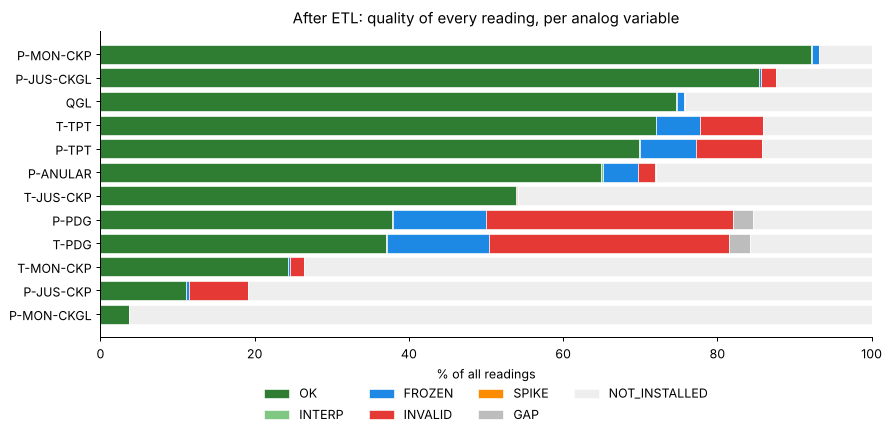

In [24]:
order = ['OK', 'INTERP', 'FROZEN', 'INVALID', 'SPIKE', 'GAP', 'NOT_INSTALLED']
colors = {'OK': '#2e7d32', 'INTERP': '#81c784', 'FROZEN': '#1e88e5', 'INVALID': '#e53935',
          'SPIKE': '#fb8c00', 'GAP': '#bdbdbd', 'NOT_INSTALLED': '#eeeeee'}
comp = pd.DataFrame({n: Q[n].value_counts(normalize=True) * 100 for n in ANALOG}).T.reindex(columns=order).fillna(0)
comp.index = [VARIABLES.set_index('name').loc[n, 'tag'] for n in comp.index]
comp = comp.sort_values('OK')
fig, ax = plt.subplots(figsize=(10, 5))
left = np.zeros(len(comp))
for c in order:
    ax.barh(comp.index, comp[c], left=left, color=colors[c], label=c, edgecolor='white', linewidth=0.5)
    left += comp[c].values
ax.set_xlabel('% of all readings'); ax.set_xlim(0, 100)
ax.set_title('After ETL: quality of every reading, per analog variable')
ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.12), frameon=False)
plt.tight_layout(); plt.savefig('outputs/figures/02_quality_composition.png', dpi=150); plt.show()

## Before / after examples
**(a)** A downhole gauge that works for part of an event and then starts sending error codes.
**(b)** A frozen downhole gauge: it reports the same pressure for hours while the subsea sensor shows a large change. Physically, both cannot be right — this is the kind of *conflicting evidence* the KBS must resolve.
Both instances are chosen automatically as the clearest cases in the data.

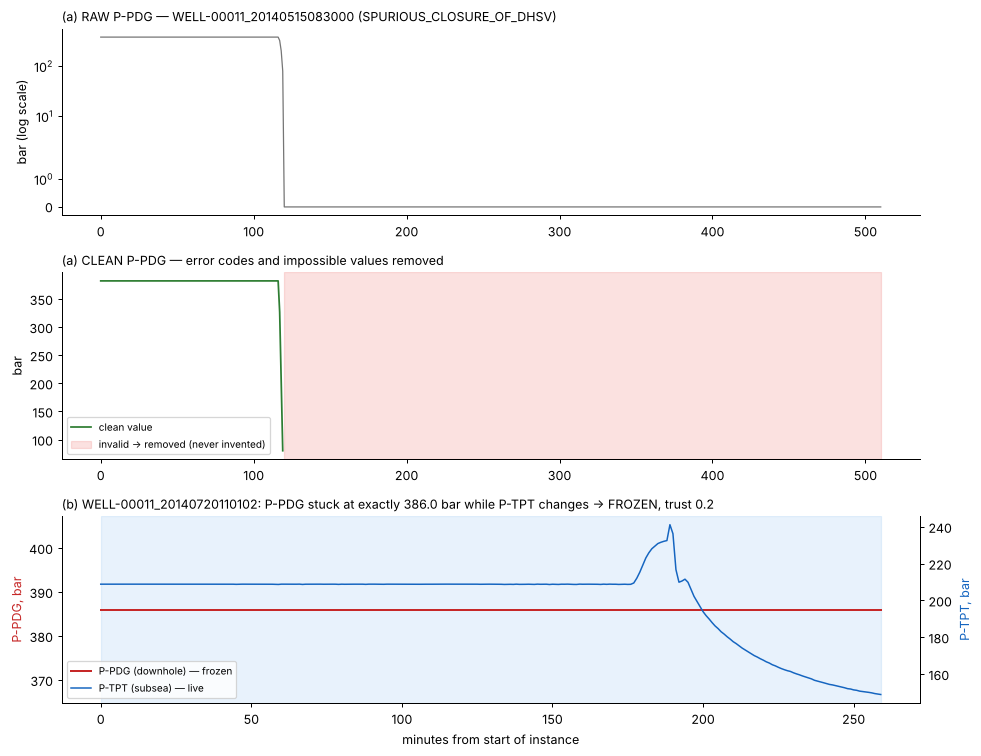

In [25]:
def pick(var, bad):
    best, score = None, -1
    for iid, grp in clean.groupby('instance_id'):
        q = grp[f'{var}_q']
        sc = min((q == 'OK').mean(), (q == bad).mean())
        if sc > score:
            best, score = iid, sc
    return best

TAG = dict(zip(VARIABLES.name, VARIABLES.tag))
ex_a = pick('p_pdg', 'INVALID')

# (b): a frozen downhole gauge during an event while the subsea sensor is live and clearly changing
def pick_frozen_conflict():
    best, change = None, -1
    for iid, grp in clean[clean.event_type > 0].groupby('instance_id'):
        if (grp.p_pdg_q == 'FROZEN').mean() >= 0.8 and (grp.p_tpt_q == 'OK').mean() >= 0.8:
            ch = grp.p_tpt.max() - grp.p_tpt.min()
            if ch > change:
                best, change = iid, ch
    return best or pick('p_tpt', 'FROZEN')
ex_b = pick_frozen_conflict()
fig, axes = plt.subplots(3, 1, figsize=(11, 8.5))

r = raw[raw.instance_id == ex_a].reset_index(drop=True)
c = clean[clean.instance_id == ex_a].reset_index(drop=True)
t = np.arange(len(c))
axes[0].plot(t, r['P-PDG'] / 1e5, color='#757575', lw=1)
axes[0].set_yscale('symlog'); axes[0].set_ylabel('bar (log scale)')
axes[0].set_title(f'(a) RAW P-PDG — {ex_a} ({c.event_name[0]})', loc='left', fontsize=10)
axes[1].plot(t, c['p_pdg'], color='#2e7d32', lw=1.4, label='clean value')
inv = c.p_pdg_q == 'INVALID'
axes[1].fill_between(t, 0, 1, where=inv, transform=axes[1].get_xaxis_transform(), color='#e53935', alpha=0.15,
                     label='invalid → removed (never invented)')
axes[1].set_ylabel('bar'); axes[1].legend(loc='lower left', fontsize=8)
axes[1].set_title('(a) CLEAN P-PDG — error codes and impossible values removed', loc='left', fontsize=10)

c = clean[clean.instance_id == ex_b].reset_index(drop=True)
t = np.arange(len(c))
fz = (c.p_pdg_q == 'FROZEN').values
axes[2].plot(t, c['p_pdg'], color='#c62828', lw=1.6, label='P-PDG (downhole) — frozen')
axes[2].set_ylabel('P-PDG, bar', color='#c62828')
ax2 = axes[2].twinx()
ax2.plot(t, c['p_tpt'], color='#1565c0', lw=1.2, label='P-TPT (subsea) — live')
ax2.set_ylabel('P-TPT, bar', color='#1565c0'); ax2.spines['right'].set_visible(True)
axes[2].fill_between(t, 0, 1, where=fz, transform=axes[2].get_xaxis_transform(), color='#1e88e5', alpha=0.10)
axes[2].set_xlabel('minutes from start of instance')
axes[2].set_title(f'(b) {ex_b}: P-PDG stuck at exactly {c.p_pdg[fz].iloc[0]:.1f} bar while P-TPT changes '
                  '→ FROZEN, trust 0.2', loc='left', fontsize=10)
h1, l1 = axes[2].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
axes[2].legend(h1 + h2, l1 + l2, loc='lower left', fontsize=8)
plt.tight_layout(); plt.savefig('outputs/figures/03_before_after_example.png', dpi=150); plt.show()

## What the KBS will see: a spurious DHSV closure as facts
Pressures for a real DHSV-closure instance (fault onset marked), and underneath, the trend facts the ETL produced for each sensor.

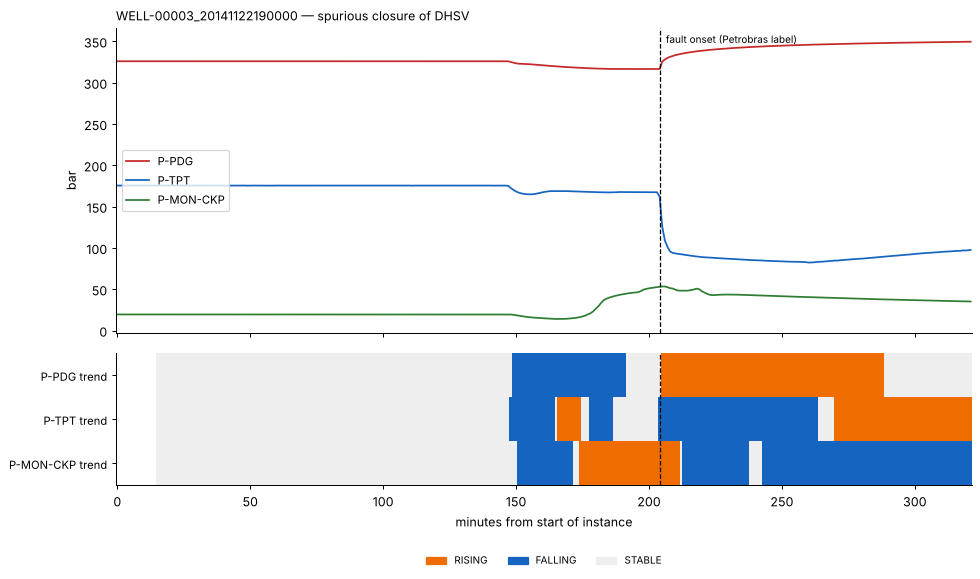

In [26]:
cand = {iid: (grp[['p_pdg_q', 'p_tpt_q', 'p_mon_ckp_q']] == 'OK').mean().mean()
        for iid, grp in clean[clean.event_type == 2].groupby('instance_id')}
ex2 = max(cand, key=cand.get)
c2 = clean[clean.instance_id == ex2].reset_index(drop=True)
f2 = facts[facts.instance_id == ex2].reset_index(drop=True)
on = instances.set_index('instance_id').loc[ex2, 'onset_minute']
t2 = np.arange(len(c2))
SENS = [('p_pdg', '#c62828'), ('p_tpt', '#1565c0'), ('p_mon_ckp', '#2e7d32')]

fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={'height_ratios': [3, 1.3]})
for n, col in SENS:
    axes[0].plot(t2, c2[n], color=col, lw=1.4, label=TAG[n])
axes[0].set_ylabel('bar'); axes[0].legend(loc='center left', fontsize=9)
axes[0].set_title(f'{ex2} — spurious closure of DHSV', loc='left', fontsize=10)

code = {'RISING': 0, 'STABLE': 1, 'FALLING': 2, 'UNKNOWN': 3}
from matplotlib.colors import ListedColormap
cmap = ListedColormap(['#ef6c00', '#eeeeee', '#1565c0', '#ffffff'])
strip = np.vstack([f2[f'{n}_trend'].map(code).values for n, _ in SENS])
axes[1].imshow(strip, aspect='auto', cmap=cmap, vmin=0, vmax=3, interpolation='nearest',
               extent=[-0.5, len(t2) - 0.5, len(SENS) - 0.5, -0.5])
axes[1].set_yticks(range(len(SENS)), [f'{TAG[n]} trend' for n, _ in SENS], fontsize=9)
axes[1].set_xlabel('minutes from start of instance')
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(color='#ef6c00', label='RISING'), Patch(color='#1565c0', label='FALLING'),
                        Patch(color='#eeeeee', label='STABLE')], ncol=3, fontsize=8,
               loc='upper center', bbox_to_anchor=(0.5, -0.45), frameon=False)
if pd.notna(on):
    for a in axes:
        a.axvline(on, color='k', ls='--', lw=1)
    axes[0].annotate('fault onset (Petrobras label)', (on, axes[0].get_ylim()[1]), xytext=(5, -12),
                     textcoords='offset points', fontsize=8)
plt.tight_layout(); plt.savefig('outputs/figures/04_dhsv_facts_example.png', dpi=150); plt.show()

## ETL summary

In [27]:
summary = {
    'input file': INPUT_FILE,
    'real instances': int(instances.shape[0]),
    'wells': int(df.well_id.nunique()),
    'minutes of data': int(len(df)),
    'empty columns dropped': len(empty_cols),
    'invalid readings removed': int(cleaning_log['invalid_total'].sum()),
    'frozen readings flagged': int(cleaning_log.get('frozen', pd.Series(0)).sum()),
    'spikes removed': int(cleaning_log.get('spikes', pd.Series(0)).sum()),
    'short gaps filled': int(cleaning_log['interpolated'].sum()),
    'symbolic fact columns': len(fact_cols),
    'database': DB_PATH,
}
with open('outputs/tables/etl_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)
con.close()
if IN_COLAB and SOURCE == 'drive':
    shutil.copy(DB_WORK, DB_PATH)
    print('Database copied to Drive:', DB_PATH)
elif IN_COLAB:
    # Uploaded files are temporary: package the results so they can be downloaded
    shutil.make_archive('/content/WellSense_ETL_results', 'zip', PROJECT_DIR, '.')
    from google.colab import files
    files.download('/content/WellSense_ETL_results.zip')
    print('Downloading WellSense_ETL_results.zip (database + outputs). Keep it for the next notebooks.')
pd.Series(summary, name='value').to_frame()

,value
input file,data/3W_real_small.csv
real instances,125
wells,40
minutes of data,65846
empty columns dropped,4
invalid readings removed,62984
frozen readings flagged,29974
spikes removed,251
short gaps filled,707
symbolic fact columns,80


**Next:** Notebook 2 builds the knowledge base (ontology and rules) and loads it into the same database. Notebook 3 runs the inference engine over the `facts` table.